In [204]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.io
from copy import deepcopy

import os
import xtrack as xt
import pickle
import at
import multiprocessing as mp

In [205]:
# Load ring and xcell
with open('candidates/n01_02_01_01/ring.pkl', 'rb') as file:
    ring = pickle.load(file)

xcell = at.load.xsuite.line_from_lattice(ring, match_model=True)

/gpfs/offline1/staff/common/alfpet/git/lattice_design/.venv/lib64/python3.12/site-packages/at/load/xsuite.py:373: AtWarning: Element 'corrh_ac' is replaced by a Marker
  return xsclass.from_at(match_model=match_model, **atelem.to_file())
/gpfs/offline1/staff/common/alfpet/git/lattice_design/.venv/lib64/python3.12/site-packages/at/load/xsuite.py:373: AtWarning: Element 'corrv_ac' is replaced by a Marker
  return xsclass.from_at(match_model=match_model, **atelem.to_file())
/gpfs/offline1/staff/common/alfpet/git/lattice_design/.venv/lib64/python3.12/site-packages/at/load/xsuite.py:373: AtWarning: Element 'corrv' is replaced by a Marker
  return xsclass.from_at(match_model=match_model, **atelem.to_file())
/gpfs/offline1/staff/common/alfpet/git/lattice_design/.venv/lib64/python3.12/site-packages/at/load/xsuite.py:373: AtWarning: Element 'corrh' is replaced by a Marker
  return xsclass.from_at(match_model=match_model, **atelem.to_file())
/gpfs/offline1/staff/common/alfpet/git/lattice_design/

Loading line from dict:   0%|          | 0/368 [00:00<?, ?it/s]

Done loading line from dict.           


In [209]:
xcell.env.elements['str0500.1']

View of Drift(length=0.5, model='expanded')

In [ ]:
xcell_ea = xt.Line(particle_ref=xcell.particle_ref.copy(), env=xcell.env,
)

for ii, (e_xt, e_at) in enumerate(zip(xcell, ring)):
    xcell_ea.append(e_at.FamName)
    xcell_ea.append(f'aperture_{ii}', xt.LimitEllipse(*e_at.EApertures))

In [ ]:
xcell_ea = xt.Line(particle_ref=xcell.particle_ref.copy(), env=xcell.env)

for i, EA in enumerate(np.unique([e.EApertures for e in ring], axis=0)):
    xcell_ea.env.elements[f'elliptic_aperature{i}'] = xt.LimitEllipse(a=EA[0], b=EA[1])

In [193]:
xcell_ea

print(xcell_ea)

Line(mode=normal, 736 elements)


In [29]:
TDR_mat = scipy.io.loadmat('candidates/n01_02_01_01/m4UT.mat', simplify_cells=True)
DAV = TDR_mat['m4U_251123_n01_02_01_01']['LattPerf']['DA']['xy_0']['outputs']['DAV']

In [41]:
def get_jacobian(xcell, x=0, px=0, y=0, py=0, zeta=0, delta=0, num_turns=20):

    tpsa = xt.ParticlesTpsa(
        order=1,
        pdg_id_0='electron',
        p0c=xcell.particle_ref.p0c,
        x=x,
        px=px,
        y=y,
        py=py,
        zeta=zeta,
        delta=delta
    )

    try:
        xcell.track(tpsa, num_turns=num_turns)
        return tpsa.jacobian()
    except:
        return np.full((6, 6), np.nan)

In [42]:
nx, ny = 100, 20
X, Y = np.meshgrid(1e-3*np.linspace(-5, 5, nx), 1e-3*np.linspace(2, 0, ny))

def wrapper(args):
    i, j = args
    jac = get_jacobian(xcell, x=X[i, j], y=Y[i, j])
    return i, j, jac

J = np.zeros((*X.shape, 6, 6))
indices = list(np.ndindex(X.shape))

with mp.Pool() as pool:
    for i, j, jac in pool.imap_unordered(wrapper, indices):
        J[i, j] = jac

In [43]:
# Calculate losses
r_in = np.zeros((6, nx*ny))
r_in[0] = X.flatten()
r_in[2] = Y.flatten()
r_out, trackparam, trackdata = at.track.lattice_track(ring, r_in, losses=True)

lost = trackdata['loss_map'].islost.reshape(ny, nx).astype(float)
lost = 1 - lost
lost[lost == 0] = np.nan

In [ ]:
print(abs(J[0, 0]).round(2))

print('Column sum:')
print(abs(J[0, 0]).round(2).sum(axis=0))

print('Row sum:')
print(abs(J[0, 0]).round(2).sum(axis=1))

[[0.95 0.63 0.8  5.17 0.   0.03]
 [0.55 0.42 0.38 1.28 0.   0.01]
 [1.5  3.08 0.1  3.11 0.   0.04]
 [0.21 0.21 0.04 0.65 0.   0.  ]
 [0.01 0.   0.   0.02 1.   0.03]
 [0.   0.   0.   0.   0.   1.  ]]
Column sum:
[ 3.22  4.34  1.32 10.23  1.    1.11]
Row sum:
[7.58 2.64 7.83 1.11 1.06 1.  ]


In [44]:
norm_col = np.zeros_like(X)
norm_row = np.zeros_like(X)
norm_F = np.zeros_like(X)
norm_eig = np.zeros_like(X)

for i, j in np.ndindex(X.shape):
    norm_col[i, j] = abs(J[i, j]).sum(axis=0).max()
    norm_row[i, j] = abs(J[i, j]).sum(axis=1).max()
    norm_F[i, j] = np.sqrt(abs(J[i, j]**2).sum())
    norm_eig[i, j] = abs(np.linalg.eigvals(J[i, j])).max() if np.isfinite(J[i, j]).all() else np.nan

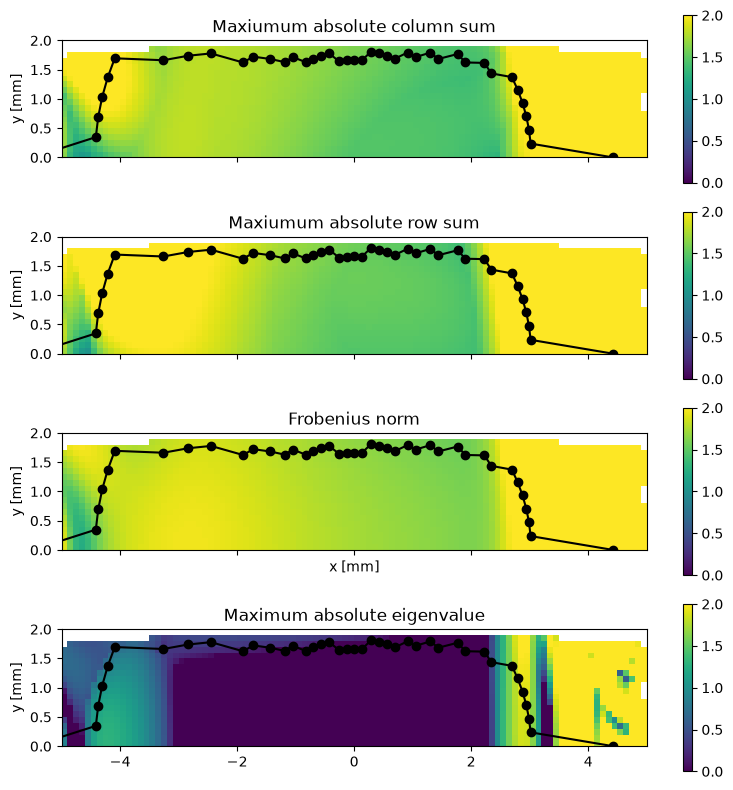

In [74]:
norms = [norm_col, norm_row, norm_F, norm_eig]
titles = ['Maxiumum absolute column sum', 'Maxiumum absolute row sum', 'Frobenius norm', 'Maximum absolute eigenvalue']
vmax = [2, 2, 2, 2]       # Set individually

fig, axs = plt.subplots(len(norms), 1, sharex=True, figsize=(8, 8))

for i in range(len(norms)):

    im = axs[i].imshow(
        np.log(norms[i])*lost,
        extent=1e3*np.array([X.min(), X.max(), Y.min(), Y.max()]),
        vmin=0,
        vmax=vmax[i]
    )

    axs[i].set_ylabel('y [mm]')
    axs[i].set_title(titles[i])
    fig.colorbar(im, ax=axs[i], location='right')

    axs[i].set_ylim(0, 2)
    axs[i].set_xlim(-5, 5)
    
    axs[i].plot(1e3*DAV[:,0], 1e3*DAV[:,1], c='black', marker='o')

axs[2].set_xlabel('x [mm]')

plt.tight_layout()

In [75]:
def in_polygon(xp, yp, x, y):
    inside = False

    j = len(x) - 1

    for i in range(len(x)):
        # Check whether the horizontal ray crosses this edge
        if (y[i] > yp) != (y[j] > yp):
            # x-coordinate where the edge intersects y = yp
            x_intersect = x[j] + (yp - y[j]) * (x[i] - x[j]) / (y[i] - y[j])

            if xp < x_intersect:
                inside = not inside

        j = i

    return inside

in_DA = np.zeros_like(X, bool)
for i, j in np.ndindex(X.shape):
    x, y = X[i, j], Y[i, j]
    if y == 0: 
        y+=1e-10 # Avoid edge case
    in_DA[i, j] = in_polygon(x, y, DAV[:,0], DAV[:,1])

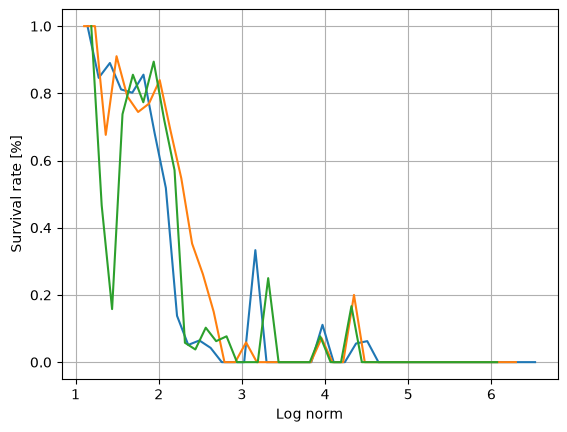

In [103]:
def get_DA_ratio(norm, min=0, max=3, log=True):
    if log: norm = np.log(norm)

    bins = np.linspace(min, max)
    count_in = np.histogram((norm*lost)[in_DA], bins)[0]
    count_out = np.histogram((norm*lost)[in_DA==False], bins)[0]
    ratio = count_in/(count_in+count_out)
    bin_centers = (bins[1:] + bins[:-1])/2
    return bin_centers, ratio

plt.plot(*get_DA_ratio(norm_col, max=np.log(np.nanmax(norm_col))))
plt.plot(*get_DA_ratio(norm_row, max=np.log(np.nanmax(norm_row))))
plt.plot(*get_DA_ratio(norm_F, max=np.log(np.nanmax(norm_F))))
# plt.plot(*get_DA_ratio(norm_eig))

plt.grid()
plt.xlabel('Log norm')
plt.ylabel('Survival rate [%]')

plt.show()

## Comparison to 1000 turns

In [111]:
Y.shape

(20, 100)

In [ ]:
particles = xcell.build_particles(x=X.flatten(), y=Y.flatten())

xcell.track(particles, num_turns=20*1e3) # Track for 1000 turns

with open('particles_1000_turns.pkl', 'wb') as file:
    pickle.dump(particles, file)

Particles(q0=-1, mass0=5.11e+05, p0c=[2.99999996e+09, 2.99999996e+09, 2.99999996e+09, ...,
                2.99999996e+09, 2.99999996e+09, 2.99999996e+09],
               shape=(2000,), gamma0=[5870.85354275, 5870.85354275, 5870.85354275, ...,
                5870.85354275, 5870.85354275, 5870.85354275],
               shape=(2000,), beta0=[0.99999999, 0.99999999, 0.99999999, ..., 0.99999999,
                0.99999999, 0.99999999], shape=(2000,), s=[ 0.     ,  0.     ,  0.     , ...,  5.925  , 14.12788,  9.27596],
      shape=(2000,), zeta=[-0.00543944, -0.00533052, -0.00491678, ..., -2.30439611,
       -2.41650364, -4.60154032], shape=(2000,), x=[-4.77654567e-03, -4.72967226e-03, -2.03123708e-03, ...,
        2.65993252e+00, -2.65427712e-01,  1.48583919e+00], shape=(2000,), y=[ 2.13832750e-03, -2.01267645e-03,  4.89511360e-04, ...,
       -4.92037151e-01, -1.31973615e+00, -3.68167682e-01], shape=(2000,), px=[ 1.00240156e-04,  1.84527108e-04, -7.19070113e-04, ...,
        1.76082711e+

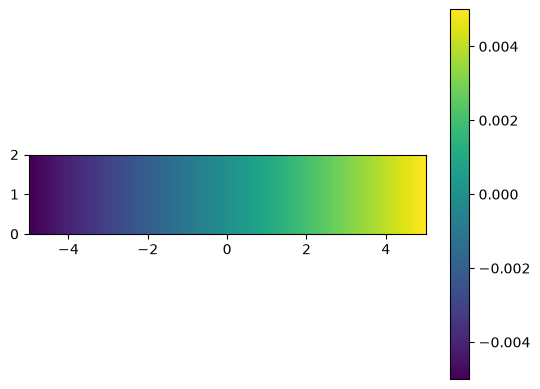

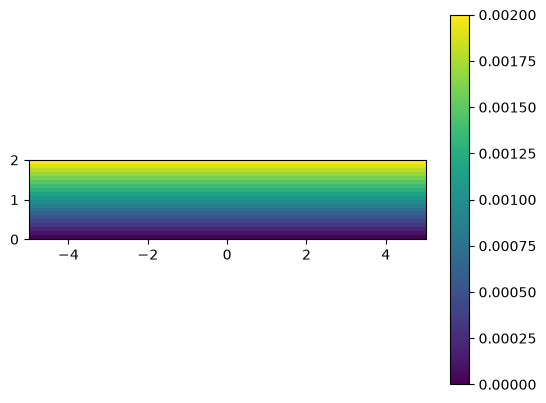

In [126]:
extent = 1e3*np.array([X.min(), X.max(), Y.min(), Y.max()])
plt.imshow(X, extent=extent)
plt.colorbar()
plt.show()

plt.imshow(Y, extent=extent)
plt.colorbar()
plt.show()

In [130]:
particles.x

array([-4.77654567e-03, -4.72967226e-03, -2.03123708e-03, ...,
        2.65993252e+00, -2.65427712e-01,  1.48583919e+00], shape=(2000,))

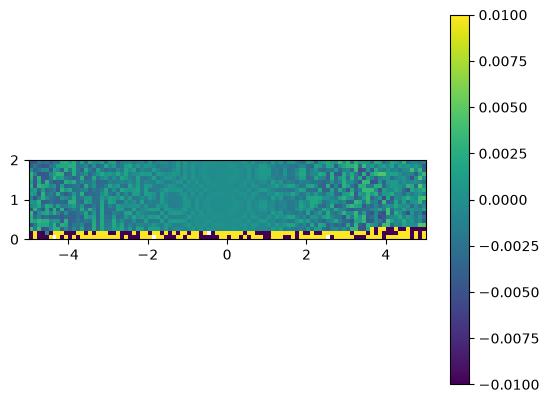

In [132]:
plt.imshow(particles.x.reshape(X.shape), extent=1e3*np.array([X.min(), X.max(), Y.min(), Y.max()]), vmin=-10e-3, vmax=10e-3)
plt.colorbar()

In [137]:
particles0 = xcell.build_particles(x=X.flatten(), y=Y.flatten())

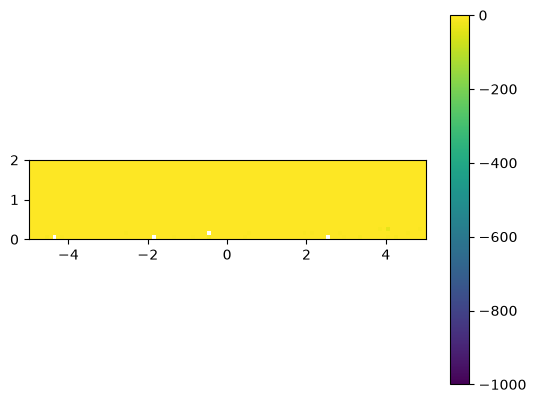

In [150]:
plt.imshow(particles.y.reshape(X.shape), extent=extent, vmin = -1e3, vmax = 1)
plt.colorbar()